# ============================================================
# Nama  : Aditia Xaverius Arapenta Tarigan
# Nim   : 42324038
# Prodi : D3 - Teknologi Informasi
# ============================================================

Perintah !pip install tensorflow saya gunakan di notebook yaitu Google Colab untuk memasang pustaka TensorFlow agar fitur komputasi numerik, machine learning, dan deep learning bisa dipakai di kode Python

In [13]:
!pip install tensorflow

 berfungsi untuk menyiapkan seluruh peralatan atau pustaka (library) Python yang dibutuhkan dalam alur kerja lengkap pembuatan model prediksi data deret waktu (time series) berbasis deep learning. Mulai dari tahap membaca dan mengolah data tabel menggunakan NumPy dan Pandas, menormalisasi skala angka serta membentuk urutan data masa lalu dengan Scikit-Learn dan TimeseriesGenerator, membangun arsitektur jaringan saraf tiruan (RNN dan LSTM) beserta fitur pencegah overfitting menggunakan TensorFlow/Keras, hingga menampilkan hasil analisis dan prediksinya dalam bentuk grafik tanggal yang rapi menggunakan Matplotlib dan Seaborn.

In [14]:
# 1. Import library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.dates as mdates


berfungsi untuk memuat data penjualan, memvisualisasikan polanya dalam bentuk grafik, serta membagi dataset menjadi data latih (train) dan data uji (test).
fungsi dari setiap bagian kode tersebut:
1. Memuat dan Merapikan Data
• dataset_path = 'RSCCASN.csv': Menentukan nama/lokasi file dataset yang akan dibaca (dataset penjualan ritel pakaian).
• sales_data = pd.read_csv(..., parse_dates=True, index_col='DATE'): Membaca file CSV ke dalam tabel (DataFrame), menjadikan kolom DATE sebagai indeks utama, serta mengubah format teks tanggal menjadi format waktu asli agar dikenali sebagai data deret waktu (time series).
• sales_data.columns = ['Sales']: Mengganti nama kolom bawaan (RSCCASN) menjadi Sales agar lebih mudah dibaca dan dipanggil.

2. Visualisasi Awal
• sales_data.plot(figsize=(12, 8)) & plt.show(): Membuat dan menampilkan grafik garis berukuran 12x8 inci untuk melihat pola historis penjualan (seperti tren kenaikan/penurunan atau pola musiman).

3. Pembagian Data (Train-Test Split)
• test_size = 18: Menetapkan bahwa 18 baris data terakhir (biasanya mewakili 18 bulan terakhir) akan disisihkan sebagai bahan ujian model.
• test_index = len(sales_data) - test_size: Menghitung titik potong indeks untuk memisahkan data lama dan data baru.
• train = sales_data.iloc[:test_index]: Mengambil seluruh data dari awal hingga sebelum titik potong untuk dijadikan data latih (bahan belajar model).
• test = sales_data.iloc[test_index:].copy(): Mengambil 18 data terakhir untuk dijadikan data uji (untuk mengevaluasi seberapa akurat prediksi model dibanding data asli). Penggunaan .copy() bertujuan membuat salinan data yang terpisah agar tidak memicu peringatan (warning) dari Pandas saat data dimodifikasi nanti.


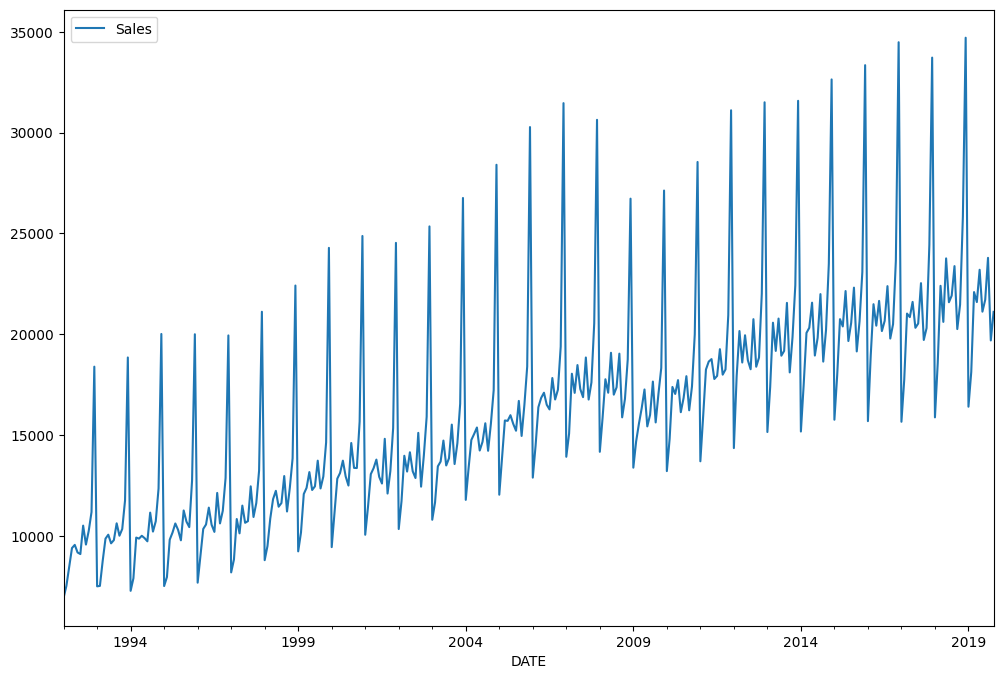

In [15]:
# 2. Pengolahan data
dataset_path = 'RSCCASN.csv'   # upload file RSCCASN.csv ke Colab dulu
sales_data = pd.read_csv(dataset_path, parse_dates=True, index_col='DATE')
sales_data.columns = ['Sales']   # RSCCASN -> Sales

# Plot data penjualan
sales_data.plot(figsize=(12, 8))
plt.show()

# Train-test split
test_size = 18
test_index = len(sales_data) - test_size
train = sales_data.iloc[:test_index]
test = sales_data.iloc[test_index:].copy()   # .copy() agar tidak muncul SettingWithCopyWarning

berfungsi untuk mengubah skala angka penjualan menjadi rentang antara 0 hingga 1 (normalisasi) agar model deep learning (RNN/LSTM) dapat belajar lebih cepat, stabil, dan akurat.

In [16]:
# 3. Normalisasi data
scaler = MinMaxScaler()
scaler.fit(train)
scaled_train = scaler.transform(train)
scaled_test = scaler.transform(test)


berfungsi untuk memotong data deret waktu menjadi paket-paket urutan (sequence) berisi pasangan "soal dan kunci jawaban" agar bisa dipelajari dan diuji oleh model RNN/LSTM.

In [17]:
# 4. Time series generator
length = 12      # panjang input (12 bulan)
n_features = 1
generator = TimeseriesGenerator(scaled_train, scaled_train, length=length, batch_size=1)

# Validation generator
validation_generator = TimeseriesGenerator(scaled_test, scaled_test, length=length, batch_size=1)


berfungsi untuk membangun, mengonfigurasi, dan melatih dua model jaringan saraf tiruan yang berbeda (SimpleRNN dan LSTM) guna membandingkan performanya dalam memprediksi data penjualan.

1. Membangun Arsitektur Model
• model_rnn = Sequential() & model_lstm = Sequential(): Membuat kerangka model berurutan (lapisan disusun dari atas ke bawah).
• Lapisan Utama (SimpleRNN(100, ...) vs LSTM(100, ...)): Menambahkan lapisan berulang dengan 100 neuron dan fungsi aktivasi relu untuk mengenali pola urutan dari 12 bulan data (input_shape=(12, 1)). SimpleRNN adalah versi dasar, sedangkan LSTM adalah versi lebih canggih yang mampu mengingat pola jangka panjang lebih baik.
• Dropout(0.2) (khusus LSTM): Mematikan secara acak 20% neuron selama proses latihan agar model tidak terlalu menghafal data latih (overfitting) dan lebih pintar saat menghadapi data baru.
• Dense(1): Lapisan output akhir berisi 1 neuron untuk mengeluarkan satu angka hasil prediksi penjualan bulan berikutnya.

2. Mengatur Cara Belajar (Compile)
• compile(optimizer='adam', loss='mse'): Menentukan algoritma pengoptimal (adam) untuk memperbarui bobot kecerdasan model, serta mengukur tingkat kesalahan menggunakan Mean Squared Error (mse). Pada model LSTM, kecepatan belajarnya diatur secara spesifik ke 0.001.
• summary(): Menampilkan ringkasan struktur lapisan dan total jumlah parameter yang akan dilatih ke layar.

3. Mencegah Latihan Berlebih (EarlyStopping)
• EarlyStopping(monitor='val_loss', patience=3 atau 5, restore_best_weights=True): Mengawasi nilai kesalahan pada data validasi (val_loss). Jika performa model tidak membaik selama 3 epoch berturut-turut (pada RNN) atau 5 epoch (pada LSTM), proses latihan akan dihentikan otomatis dan model akan mengembalikan bobot terbaiknya.

4. Proses Pelatihan (Training)
• fit(generator, epochs=20, ...): Memulai proses belajar model menggunakan data dari generator maksimal sebanyak 20 putaran (epochs), sambil terus dievaluasi menggunakan validation_generator dan dijaga oleh EarlyStopping. Riwayat skor kesalahan tiap putaran disimpan ke dalam variabel history_rnn dan history_lstm.


In [18]:
# 5a. Model SimpleRNN
model_rnn = Sequential()
model_rnn.add(SimpleRNN(100, activation='relu', input_shape=(length, n_features)))
model_rnn.add(Dense(1))
model_rnn.compile(optimizer='adam', loss='mse')
model_rnn.summary()

early_stop_rnn = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history_rnn = model_rnn.fit(generator, epochs=20,
                            validation_data=validation_generator,
                            callbacks=[early_stop_rnn])

# 5b. Model LSTM (dengan Dropout)
model_lstm = Sequential()
model_lstm.add(LSTM(100, activation='relu', input_shape=(length, n_features)))
model_lstm.add(Dropout(0.2))   # mengurangi overfitting
model_lstm.add(Dense(1))
model_lstm.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse')
model_lstm.summary()

early_stop_lstm = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history_lstm = model_lstm.fit(generator, epochs=20,
                              validation_data=validation_generator,
                              callbacks=[early_stop_lstm])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_2 (SimpleRNN)        │ (None, 100)            │        10,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,301 (40.24 KB)

 Trainable params: 10,301 (40.24 KB)

 Non-trainable params: 0 (0.00 B)

... (3 outputs left out)

 Total params: 40,901 (159.77 KB)

 Trainable params: 40,901 (159.77 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.0303 - val_loss: 0.0104
Epoch 2/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0175 - val_loss: 0.0045
Epoch 3/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0114 - val_loss: 0.0125
Epoch 4/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0080 - val_loss: 0.0012
Epoch 5/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0050 - val_loss: 5.3716e-04
Epoch 6/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0047 - val_loss: 0.0013
Epoch 7/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0029 - val_loss: 0.0053
Epoch 8/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0022 - val_loss: 7.5680e-04
Epoch 9/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0038 - val_loss: 4.1939e-04
Epoch 10/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0029 - val_loss: 0.0015
Epoch 11/20
304/304 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0034 - val_loss: 3.3611e-04
Epoch 12/20
304/304 ━━━━━━━━━━━━━━━━

berfungsi untuk memvisualisasikan dan membandingkan grafik tingkat kesalahan (loss) selama proses pelatihan antara model SimpleRNN dan LSTM guna mengevaluasi seberapa baik keduanya belajar dan mendeteksi tanda-tanda overfitting.

• plot_loss(history_rnn, history_lstm): Menggabungkan empat garis kesalahan (RNN Loss, RNN Val Loss, LSTM Loss, dan LSTM Val Loss) dalam satu grafik agar Anda bisa membandingkan secara langsung model mana yang kesalahannya paling rendah dan paling stabil di setiap epoch.
• plot_loss_rnn(history_rnn): Menampilkan grafik kesalahan khusus untuk model SimpleRNN saja (membandingkan kesalahan data latih loss vs data validasi val_loss) agar pergerakan kurvanya terlihat lebih jelas tanpa tertumpuk garis model lain.
• plot_loss_lstm(history_lstm): Menampilkan grafik kesalahan khusus untuk model LSTM saja dengan tujuan yang sama.


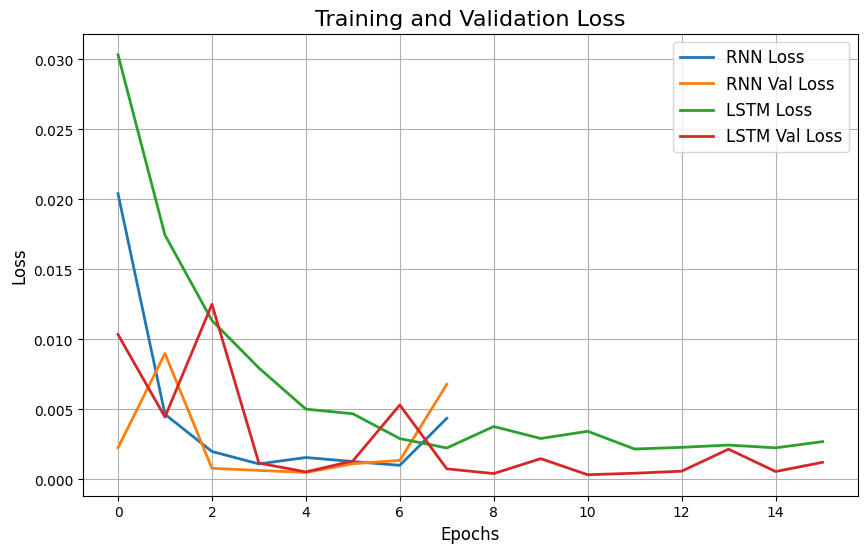

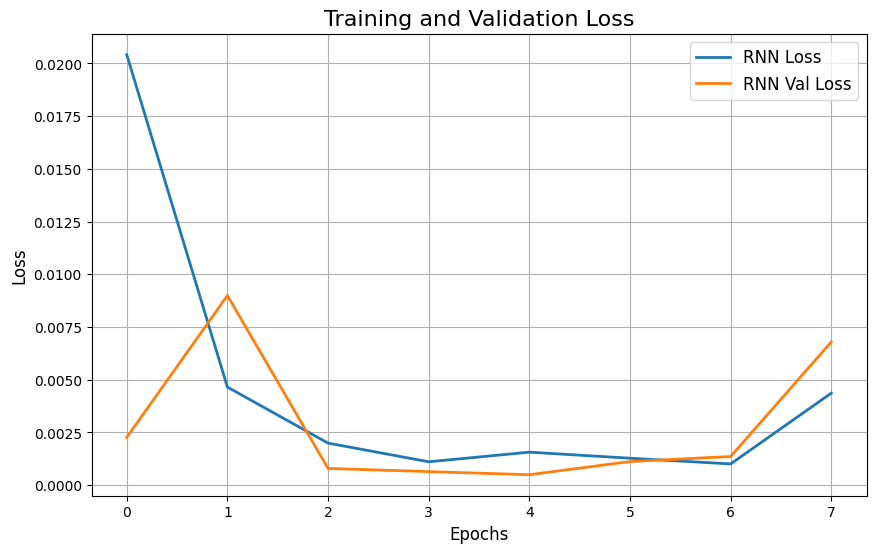

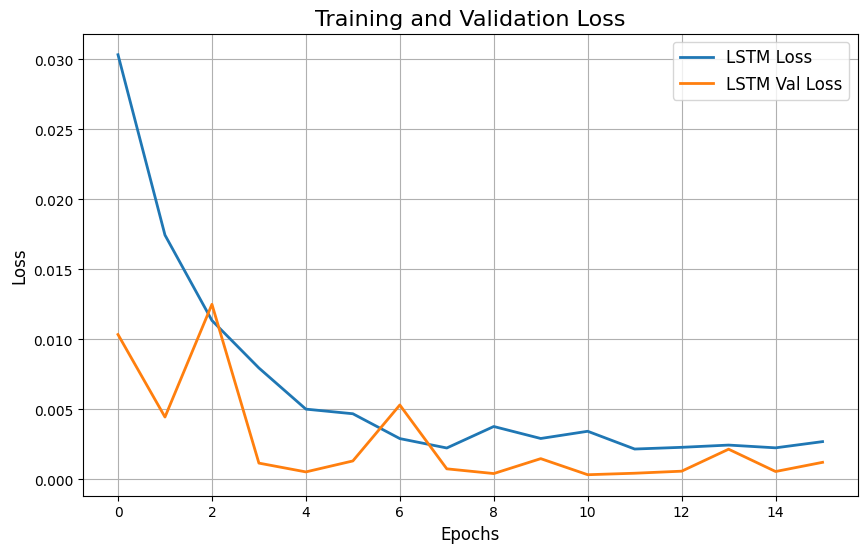

In [19]:
# 6. Evaluasi model
def plot_loss(history_rnn, history_lstm):
    losses_rnn = pd.DataFrame(history_rnn.history)
    losses_lstm = pd.DataFrame(history_lstm.history)

    plt.figure(figsize=(10, 6))
    plt.plot(losses_rnn['loss'], label='RNN Loss', linewidth=2)
    plt.plot(losses_rnn['val_loss'], label='RNN Val Loss', linewidth=2)
    plt.plot(losses_lstm['loss'], label='LSTM Loss', linewidth=2)
    plt.plot(losses_lstm['val_loss'], label='LSTM Val Loss', linewidth=2)
    plt.title('Training and Validation Loss', fontsize=16)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.show()

plot_loss(history_rnn, history_lstm)


def plot_loss_rnn(history_rnn):
    losses_rnn = pd.DataFrame(history_rnn.history)
    plt.figure(figsize=(10, 6))
    plt.plot(losses_rnn['loss'], label='RNN Loss', linewidth=2)
    plt.plot(losses_rnn['val_loss'], label='RNN Val Loss', linewidth=2)
    plt.title('Training and Validation Loss', fontsize=16)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.show()


def plot_loss_lstm(history_lstm):
    losses_lstm = pd.DataFrame(history_lstm.history)
    plt.figure(figsize=(10, 6))
    plt.plot(losses_lstm['loss'], label='LSTM Loss', linewidth=2)
    plt.plot(losses_lstm['val_loss'], label='LSTM Val Loss', linewidth=2)
    plt.title('Training and Validation Loss', fontsize=16)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.show()

plot_loss_rnn(history_rnn)
plot_loss_lstm(history_lstm)


 berfungsi untuk menghasilkan prediksi penjualan berantai ke masa depan (forecasting) selama 18 bulan ke depan menggunakan model SimpleRNN dan LSTM, lalu membandingkan hasilnya secara visual dengan data penjualan asli.

1. Fungsi Prediksi Berantai (make_predictions)
• first_eval_batch = scaled_data[-length:]: Mengambil 12 data bulan terakhir dari data latih (scaled_train) sebagai modal awal untuk menebak bulan ke-1 pada data uji.
• current_batch = first_eval_batch.reshape((1, length, n_features)): Mengubah bentuk data menjadi 3 dimensi (1 paket, 12 bulan, 1 fitur) sesuai syarat input model Keras.
• Perulangan for i in range(len(test)): Melakukan tebakan satu per satu sebanyak jumlah data uji (18 bulan):
	• current_pred = model.predict(current_batch)[0]: Model menebak angka penjualan 1 bulan ke depan.
	• predictions.append(current_pred): Menyimpan hasil tebakan ke dalam daftar.
	• current_batch = np.append(current_batch[:, 1:, :], [[current_pred]], axis=1): Menggeser jendela waktu (sliding window)—membuang data bulan paling lama di urutan pertama, lalu memasukkan hasil tebakan barusan ke urutan paling akhir. Hasil tebakan ini kemudian dipakai lagi sebagai modal untuk menebak bulan berikutnya.
• return scaler.inverse_transform(predictions): Mengembalikan seluruh angka tebakan yang tadinya berskala 0–1 kembali ke satuan nilai penjualan aslinya.

2. Menyimpan Hasil Prediksi
• rnn_predictions & lstm_predictions: Menjalankan fungsi prediksi di atas untuk masing-masing model, lalu menyimpannya sebagai kolom baru (RNN_Predictions dan LSTM_Predictions) di dalam tabel test agar berdampingan langsung dengan angka penjualan asli (Sales).

3. Visualisasi Perbandingan (plot_predictions)
• plt.plot(...): Menggambar tiga garis dalam satu grafik untuk membandingkan penjualan asli (Actual Sales berwarna biru) melawan hasil tebakan RNN (garis putus-putus oranye) dan LSTM (garis putus-putus hijau).
• mdates.DateFormatter('%b %Y') & MonthLocator(interval=3): Mengatur tampilan tanggal pada sumbu bawah agar muncul rapi setiap 3 bulan sekali dengan format singkat (contoh: Jan 2019, Apr 2019).


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━

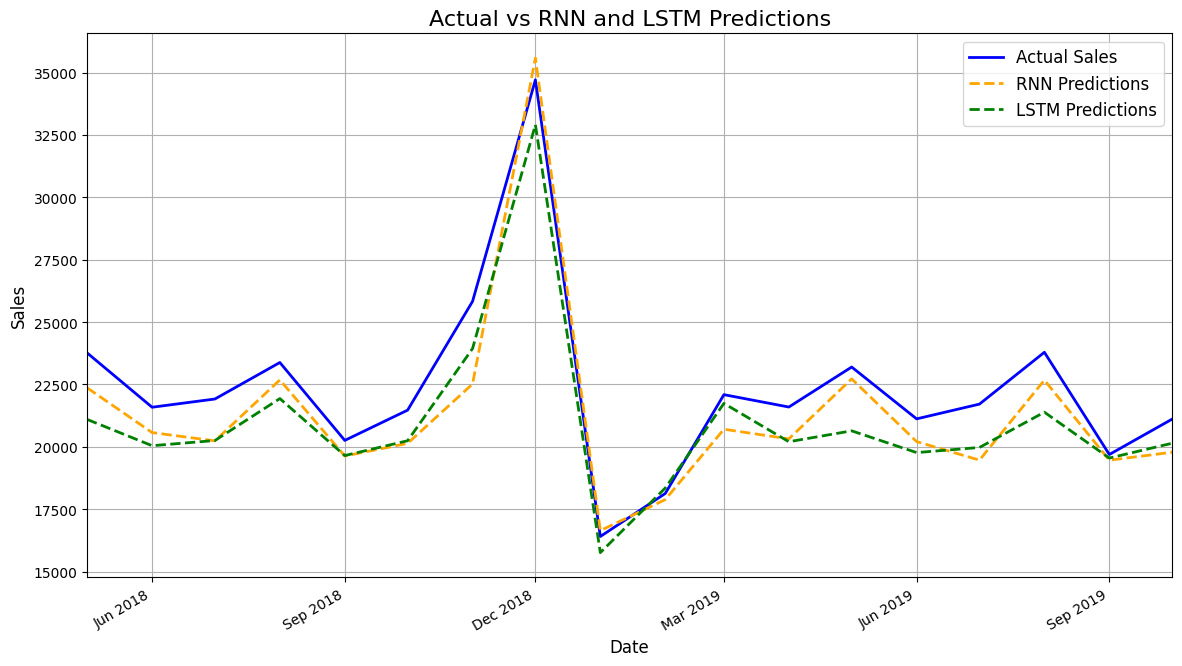

In [20]:
# 6. Prediksi data test
def make_predictions(model, scaled_data, length, n_features):
    predictions = []
    first_eval_batch = scaled_data[-length:]
    current_batch = first_eval_batch.reshape((1, length, n_features))

    for i in range(len(test)):
        current_pred = model.predict(current_batch)[0]
        predictions.append(current_pred)
        current_batch = np.append(current_batch[:, 1:, :], [[current_pred]], axis=1)

    return scaler.inverse_transform(predictions)

rnn_predictions = make_predictions(model_rnn, scaled_train, length, n_features)
lstm_predictions = make_predictions(model_lstm, scaled_train, length, n_features)

test['RNN_Predictions'] = rnn_predictions
test['LSTM_Predictions'] = lstm_predictions


def plot_predictions(test, sales_data, rnn_predictions, lstm_predictions):
    plt.figure(figsize=(14, 8))
    plt.plot(test.index, test['Sales'], label='Actual Sales', color='blue', linewidth=2)
    plt.plot(test.index, test['RNN_Predictions'], label='RNN Predictions',
             color='orange', linestyle='--', linewidth=2)
    plt.plot(test.index, test['LSTM_Predictions'], label='LSTM Predictions',
             color='green', linestyle='--', linewidth=2)

    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    plt.gcf().autofmt_xdate()

    plt.title('Actual vs RNN and LSTM Predictions', fontsize=16)
    plt.xlabel('Date', fontsize=12)
    plt.ylabel('Sales', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.xlim([test.index[0], test.index[-1]])
    plt.show()

plot_predictions(test, sales_data, rnn_predictions, lstm_predictions)


berfungsi untuk memproyeksikan (meramal) angka penjualan selama 12 bulan ke depan setelah akhir dataset, lalu menggabungkannya dengan data penjualan historis dalam satu grafik sambung.

1. Fungsi Peramalan Masa Depan (forecast_future)
• Cara kerjanya sama persis dengan make_predictions sebelumnya, tetapi lebih fleksibel karena jumlah bulan yang diramal diatur melalui parameter periods=12 (12 bulan ke depan).
• Model menebak bulan pertama dari 12 data terakhir, lalu memakai hasil tebakan tersebut untuk menebak bulan-bulan berikutnya secara berantai, hingga akhirnya dikembalikan ke nilai penjualan asli menggunakan scaler.inverse_transform().

2. Membuat Indeks Tanggal Baru
• pd.date_range(start='2019-11-01', periods=12, freq='MS'): Membuat daftar 12 tanggal otomatis dengan frekuensi awal bulan (MS = Month Start) untuk menjadi label waktu pada tabel hasil ramalan (forecast_rnn_data dan forecast_lstm_data).

3. Menyambungkan Garis Grafik (plot_forecast)
• Menyesuaikan Tanggal Mulai: Mengatur ulang tanggal ramalan agar dimulai tepat 1 bulan setelah tanggal terakhir di data asli (last_actual_date + pd.DateOffset(months=1)).
• Menyambung Titik Awal (pd.concat): Menyisipkan nilai dan tanggal penjualan asli yang paling terakhir ke baris paling atas data ramalan. Tujuannya agar garis prediksi (oranye dan hijau) tersambung mulus tanpa celah putus dari ujung garis penjualan asli (biru).
• plt.xlim(...): Memperbesar tampilan grafik (zoom in) hanya pada rentang waktu Januari 2018 hingga Desember 2020 agar tren data terakhir dan proyeksi masa depannya terlihat jelas.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


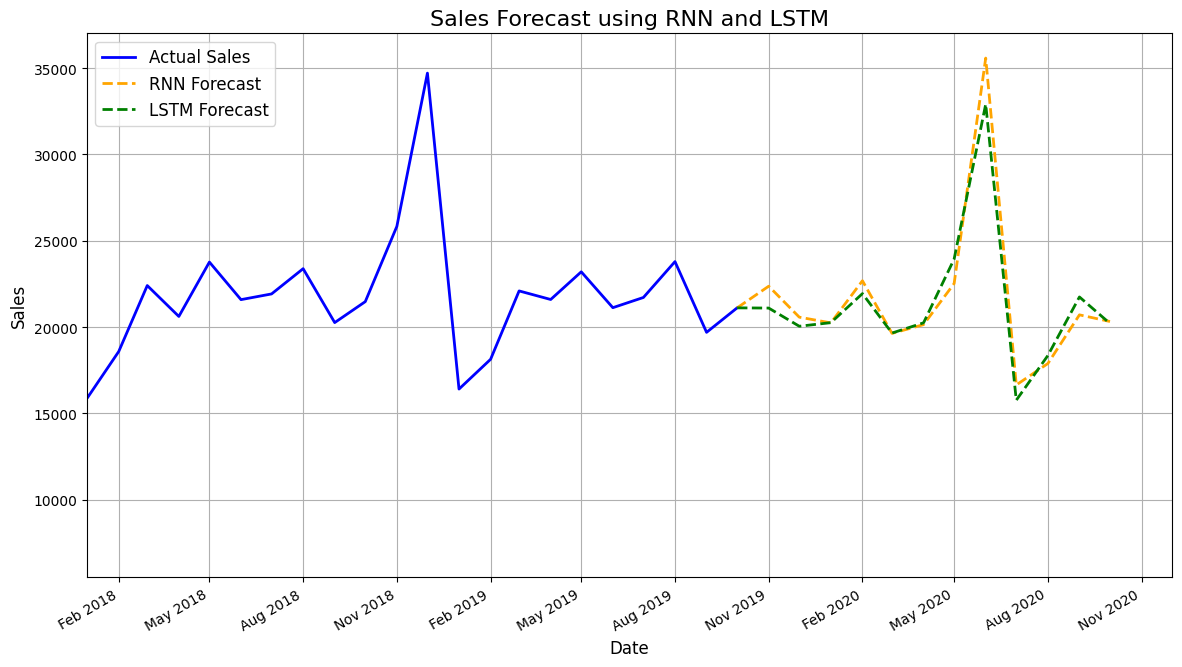

In [21]:
# 7. Prediksi jangka panjang (12 bulan ke depan)
def forecast_future(model, scaled_data, length, n_features, periods):
    forecast = []
    first_eval_batch = scaled_data[-length:]
    current_batch = first_eval_batch.reshape((1, length, n_features))

    for i in range(periods):
        current_pred = model.predict(current_batch)[0]
        forecast.append(current_pred)
        current_batch = np.append(current_batch[:, 1:, :], [[current_pred]], axis=1)

    return scaler.inverse_transform(forecast)

forecast_rnn = forecast_future(model_rnn, scaled_train, length, n_features, periods=12)
forecast_lstm = forecast_future(model_lstm, scaled_train, length, n_features, periods=12)

forecast_index = pd.date_range(start='2019-11-01', periods=12, freq='MS')
forecast_rnn_data = pd.DataFrame(data=forecast_rnn, index=forecast_index, columns=['RNN_Forecast'])
forecast_lstm_data = pd.DataFrame(data=forecast_lstm, index=forecast_index, columns=['LSTM_Forecast'])


def plot_forecast(sales_data, forecast_rnn_data, forecast_lstm_data):
    last_actual_value = sales_data['Sales'].iloc[-1]
    last_actual_date = sales_data.index[-1]

    # Susun prediksi agar dimulai tepat setelah data aktual
    forecast_rnn_data.index = pd.date_range(
        start=last_actual_date + pd.DateOffset(months=1),
        periods=len(forecast_rnn_data), freq='MS')
    forecast_lstm_data.index = pd.date_range(
        start=last_actual_date + pd.DateOffset(months=1),
        periods=len(forecast_lstm_data), freq='MS')

    # Tambahkan nilai aktual terakhir sebagai titik awal prediksi
    forecast_rnn_data = pd.concat([
        pd.DataFrame({'RNN_Forecast': [last_actual_value]}, index=[last_actual_date]),
        forecast_rnn_data])
    forecast_lstm_data = pd.concat([
        pd.DataFrame({'LSTM_Forecast': [last_actual_value]}, index=[last_actual_date]),
        forecast_lstm_data])

    # Plot
    plt.figure(figsize=(14, 8))
    plt.plot(sales_data.index, sales_data['Sales'], label='Actual Sales', color='blue', linewidth=2)
    plt.plot(forecast_rnn_data.index, forecast_rnn_data['RNN_Forecast'],
             label='RNN Forecast', color='orange', linestyle='--', linewidth=2)
    plt.plot(forecast_lstm_data.index, forecast_lstm_data['LSTM_Forecast'],
             label='LSTM Forecast', color='green', linestyle='--', linewidth=2)

    plt.xlim(pd.to_datetime('2018-01-01'), pd.to_datetime('2020-12-01'))
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    plt.gcf().autofmt_xdate()

    plt.title('Sales Forecast using RNN and LSTM', fontsize=16)
    plt.xlabel('Date', fontsize=12)
    plt.ylabel('Sales', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.show()

plot_forecast(sales_data, forecast_rnn_data, forecast_lstm_data)